# 2.3 Bayes ngây thơ (Naive Bayes)
### 2.3.1. Ôn tập lý thuyết (7 câu hỏi)

### Câu 1. Naive Bayes hoạt động như thế nào? Định lý Bayes và giả định ngây thơ
Định lý Bayes:
$$P(C\mid X)=\frac{P(X\mid C)P(C)}{P(X)}.$$
Trong đó P(C) là xác suất tiên nghiệm của lớp; P(X|C) là khả năng quan sát đặc trưng khi biết lớp; P(C|X) là xác suất hậu nghiệm. Mô hình ước lượng các đại lượng từ Train rồi chọn lớp có xác suất hậu nghiệm cao nhất.
Giả định các đặc trưng độc lập có điều kiện theo lớp cho phép phân tích:
$$\hat C=\arg\max_C P(C)\prod_j P(x_j\mid C).$$
Thực tế triển khai dùng log để tránh tích nhiều xác suất nhỏ gây tràn dưới.

### Câu 2. Gaussian, Multinomial và Bernoulli khác nhau ra sao?
| Mô hình | Giả định/đầu vào | Khi dùng |
|---|---|---|
| GaussianNB | Đặc trưng liên tục có phân phối Gaussian trong từng lớp | Tuổi, thu nhập, các số đo liên tục |
| MultinomialNB | Số đếm không âm, thường là tần suất từ | Phân loại văn bản bằng CountVectorizer |
| BernoulliNB | Mỗi đặc trưng là có/không (0/1), xét cả sự vắng mặt | Từ có xuất hiện trong văn bản hay không |
Không có biến thể nào luôn tốt nhất; cần đánh giá trên dữ liệu cụ thể.

### Câu 3. Tại sao gọi là ngây thơ? Ảnh hưởng của giả định độc lập
Tên gọi xuất phát từ việc giả định đặc trưng độc lập **khi đã biết lớp**, dù trong dữ liệu nhiều đặc trưng có tương quan. Ví dụ các từ trong một cụm từ không độc lập hoàn toàn. Giả định này giúp giảm số tham số và huấn luyện nhanh, nhưng có thể đếm lặp thông tin, bỏ qua tương tác và làm xác suất dự đoán kém tin cậy. Phân loại vẫn có thể tốt ngay cả khi xác suất chưa chính xác.

### Câu 4. Ưu điểm và hạn chế so với SVM, Random Forest
- Naive Bayes thường huấn luyện nhanh, dùng ít bộ nhớ và phù hợp văn bản nhiều chiều, dữ liệu thưa.
- Hạn chế là giả định độc lập và phân phối; khó học tương tác phức tạp.
- SVM có thể học biên phân loại linh hoạt qua kernel nhưng nhạy với scaling và tham số; kernel phi tuyến có thể tốn thời gian trên tập lớn.
- Random Forest học quan hệ phi tuyến và tương tác mà không cần giả định độc lập, nhưng nhiều cây cần thêm tài nguyên và khó diễn giải hơn một mô hình đơn giản.
So sánh cần cùng cách chia dữ liệu và chỉ số đánh giá, không khẳng định thuật toán nào luôn vượt trội.

### Câu 5. Code mẫu GaussianNB và các bước
Ô ví dụ Iris bên dưới thực hiện: nạp dữ liệu → chia Train/Test có stratify → tạo GaussianNB → fit trên Train → predict và tính Accuracy trên Test. Iris có sẵn nên không cần tải CSV cho ví dụ lý thuyết.

### Câu 6. Xử lý dữ liệu phân loại trước MultinomialNB
Điền giá trị thiếu trên Train rồi dùng OneHotEncoder để chuyển mỗi nhóm thành cột 0/1 không âm. Không dùng mã 0, 1, 2 tùy ý như các số đếm có ý nghĩa. Encoder chỉ fit trên Train và transform Test; handle_unknown='ignore' xử lý nhóm chưa thấy. Pipeline mushroom bên dưới minh họa đầy đủ. Với dữ liệu nhóm thuần túy, CategoricalNB cũng là một lựa chọn khác.

### Câu 7. Triển khai Naive Bayes cho phân loại văn bản
Làm sạch tin nhắn thiếu/trùng → chia Train/Test → CountVectorizer học từ vựng từ Train, biến mỗi tin nhắn thành vector số lần xuất hiện từ → MultinomialNB học mối liên hệ giữa từ và nhãn → dự đoán → đánh giá Accuracy, Precision, Recall, F1 và ma trận nhầm lẫn.
Tham số alpha làm trơn để hạn chế xác suất bằng 0 khi một từ chưa xuất hiện trong một lớp ở Train. Nếu tìm alpha, đặt cả vectorizer và model trong Pipeline rồi chạy CV trên Train. Test chỉ dùng đánh giá, không chọn tham số.

Notebook dùng Train/Test 80/20 và 4-fold CV trong Train. Các bước học thống kê và từ vựng được thực hiện riêng trong từng fold.


### Ví dụ: GaussianNB trên bộ dữ liệu Iris

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.datasets import load_iris

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42
)
model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))

Accuracy: 1.0


### 2.3.2. Bài toán 1: Phân loại Email Spam
#### 1. Đọc và khám phá dữ liệu

In [2]:
spam_data = pd.read_csv('../data/spam.csv', encoding='latin-1')
spam_data = spam_data[['v1', 'v2']]
spam_data.columns = ['label', 'text']

print(spam_data.head())
print(spam_data.shape)
print(spam_data.isna().sum())
print(spam_data['label'].value_counts())

  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
(5572, 2)
label    0
text     0
dtype: int64
label
ham     4825
spam     747
Name: count, dtype: int64


#### 2. Biểu đồ phân bố nhãn

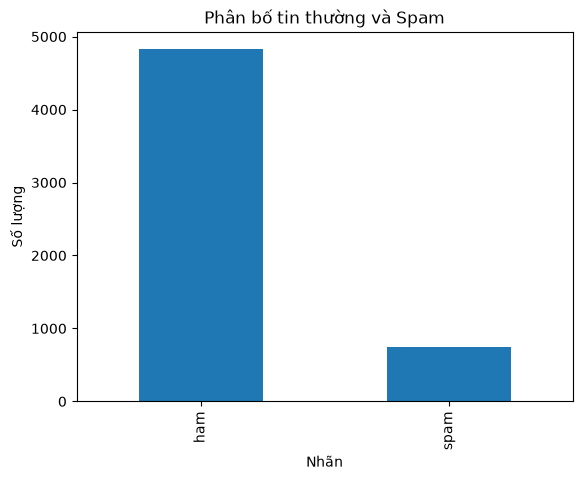

In [3]:
spam_data['label'].value_counts().plot(kind='bar')
plt.title('Phân bố tin thường và Spam')
plt.xlabel('Nhãn')
plt.ylabel('Số lượng')
plt.show()

#### 3. Tiền xử lý và chia Train/Test

In [4]:
spam_data = spam_data.dropna().drop_duplicates(subset='text')
spam_data['label'] = spam_data['label'].map({'ham': 0, 'spam': 1})

X = spam_data['text']
y = spam_data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
print(X_train_vec.shape, X_test_vec.shape)

(4135, 7709) (1034, 7709)


#### 4. Huấn luyện MultinomialNB

In [5]:
spam_model = MultinomialNB()
spam_model.fit(X_train_vec, y_train)
spam_pred = spam_model.predict(X_test_vec)

print('Accuracy:', accuracy_score(y_test, spam_pred))
print(classification_report(y_test, spam_pred))

Accuracy: 0.9825918762088974
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       903
           1       0.96      0.90      0.93       131

    accuracy                           0.98      1034
   macro avg       0.97      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



#### 5. Đánh giá bằng Confusion Matrix

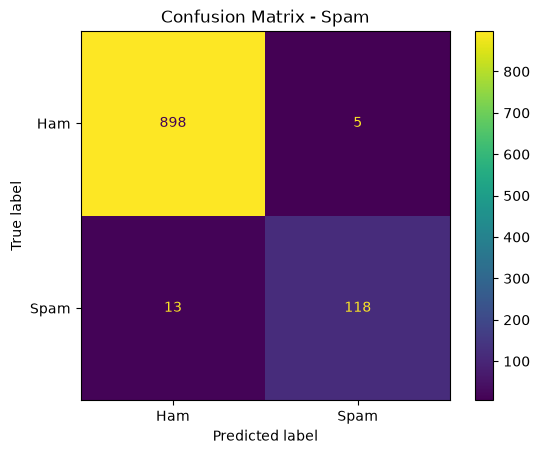

In [6]:
ConfusionMatrixDisplay.from_predictions(y_test, spam_pred, display_labels=['Ham', 'Spam'])
plt.title('Confusion Matrix - Spam')
plt.show()

#### 6. Thử dự đoán tin nhắn mới

In [7]:
new_text = ['Hello, how are you?', 'Congratulations! You won a free prize!']
new_vec = vectorizer.transform(new_text)
print(spam_model.predict(new_vec))

[0 1]


### 2.3.3. Bài tập 1: Customer Behaviour
#### 1. Đọc và khám phá dữ liệu

In [8]:
customer_data = pd.read_csv('../data/Customer_Behaviour.csv')
print(customer_data.head())
print(customer_data.shape)
print(customer_data.isna().sum())
print(customer_data['Purchased'].value_counts())

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
(400, 5)
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Purchased
0    257
1    143
Name: count, dtype: int64


#### 2. Biểu đồ nhãn Purchased

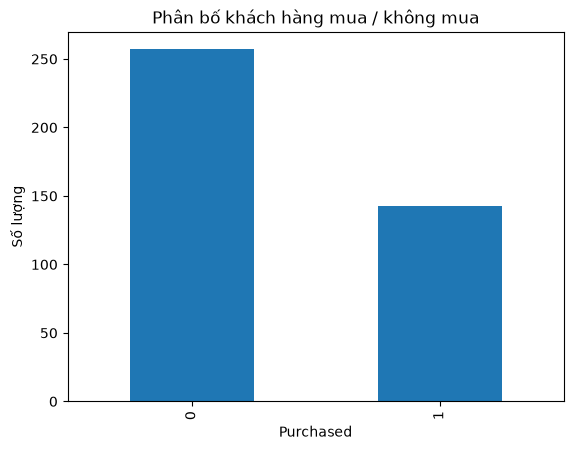

In [9]:
customer_data['Purchased'].value_counts().plot(kind='bar')
plt.title('Phân bố khách hàng mua / không mua')
plt.xlabel('Purchased')
plt.ylabel('Số lượng')
plt.show()

#### 3. Tiền xử lý và chia Train/Test

In [10]:
customer_data = customer_data.drop_duplicates()
X = customer_data[['Age', 'EstimatedSalary', 'Gender']].copy()
y = customer_data['Purchased']

X['Age'] = X['Age'].fillna(X['Age'].median())
X['EstimatedSalary'] = X['EstimatedSalary'].fillna(X['EstimatedSalary'].median())
X['Gender'] = X['Gender'].fillna(X['Gender'].mode()[0])
X = pd.get_dummies(X, columns=['Gender'], dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(320, 4) (80, 4)


#### 4. Huấn luyện GaussianNB

In [11]:
customer_model = GaussianNB()
customer_model.fit(X_train, y_train)
customer_pred = customer_model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, customer_pred))
print(classification_report(y_test, customer_pred))

Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.89      0.92      0.90        51
           1       0.85      0.79      0.82        29

    accuracy                           0.88        80
   macro avg       0.87      0.86      0.86        80
weighted avg       0.87      0.88      0.87        80



#### 5. Confusion Matrix và các mẫu dự đoán sai

     Age  EstimatedSalary  Gender_Female  Gender_Male  Thuc_te  Du_doan
234   38           112000              1            0        0        1
64    59            83000              1            0        0        1
298   45            79000              0            1        0        1
97    28           123000              0            1        1        0
209   46            22000              1            0        0        1


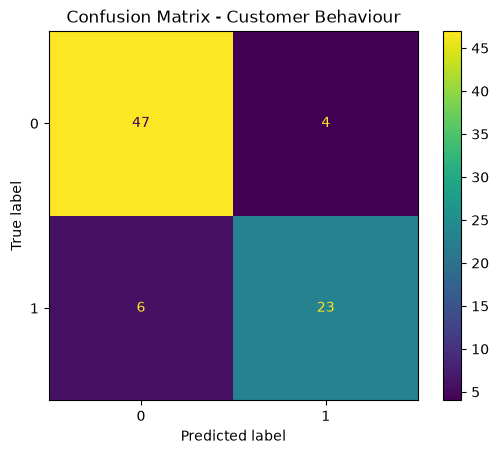

In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, customer_pred)
plt.title('Confusion Matrix - Customer Behaviour')
plt.show()

customer_result = X_test.copy()
customer_result['Thuc_te'] = y_test
customer_result['Du_doan'] = customer_pred
print(customer_result[customer_result['Thuc_te'] != customer_result['Du_doan']].head())

### 2.3.4. Bài tập 2: Mushroom Classification
#### 1. Đọc và khám phá dữ liệu

In [13]:
mushroom_data = pd.read_csv('../data/mushrooms.csv', na_values='?')
print(mushroom_data.head())
print(mushroom_data.shape)
print(mushroom_data.isna().sum())
print(mushroom_data['class'].value_counts())

  class cap-shape cap-surface  ... spore-print-color population habitat
0     p         x           s  ...                 k          s       u
1     e         x           s  ...                 n          n       g
2     e         b           s  ...                 n          n       m
3     p         x           y  ...                 k          s       u
4     e         x           s  ...                 n          a       g

[5 rows x 23 columns]
(8124, 23)
class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-t

#### 2. Biểu đồ phân bố lớp nấm

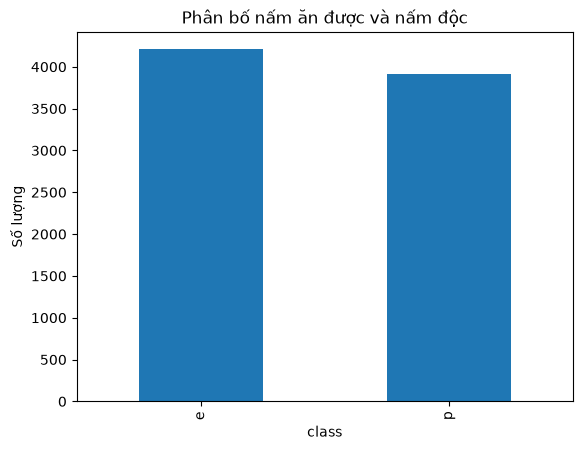

In [14]:
mushroom_data['class'].value_counts().plot(kind='bar')
plt.title('Phân bố nấm ăn được và nấm độc')
plt.xlabel('class')
plt.ylabel('Số lượng')
plt.show()

#### 3. Mã hóa dữ liệu và chia Train/Test

In [15]:
mushroom_data = mushroom_data.drop_duplicates()
X = mushroom_data.drop(columns=['class']).copy()
y = mushroom_data['class'].map({'e': 0, 'p': 1})

X = X.fillna(X.mode().iloc[0])
X = pd.get_dummies(X, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(6499, 116) (1625, 116)


#### 4. Huấn luyện MultinomialNB

In [16]:
mushroom_model = MultinomialNB()
mushroom_model.fit(X_train, y_train)
mushroom_pred = mushroom_model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, mushroom_pred))
print(classification_report(y_test, mushroom_pred))

Accuracy: 0.947076923076923
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       842
           1       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.95      0.95      1625
weighted avg       0.95      0.95      0.95      1625



#### 5. Confusion Matrix và phân tích lỗi

Số mẫu sai: 86
Nấm độc bị dự đoán là ăn được: 78


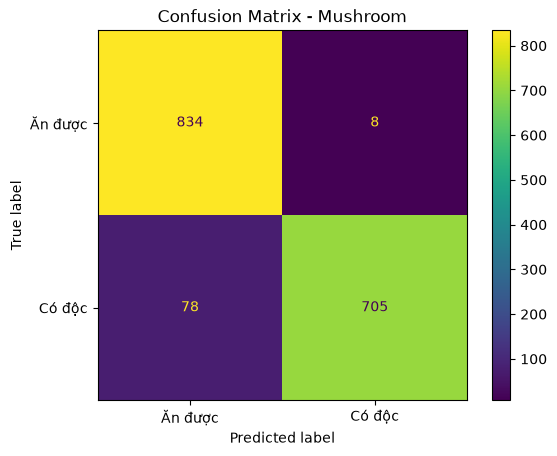

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test, mushroom_pred, display_labels=['Ăn được', 'Có độc']
)
plt.title('Confusion Matrix - Mushroom')
plt.show()

mushroom_result = X_test.copy()
mushroom_result['Thuc_te'] = y_test
mushroom_result['Du_doan'] = mushroom_pred
print('Số mẫu sai:', (mushroom_result['Thuc_te'] != mushroom_result['Du_doan']).sum())
print('Nấm độc bị dự đoán là ăn được:', ((y_test == 1) & (mushroom_pred == 0)).sum())

### Nhận xét chung
- **Spam:** Sử dụng CountVectorizer kết hợp MultinomialNB để phân loại văn bản.
- **Customer Behaviour:** Sử dụng GaussianNB cho dữ liệu khách hàng.
- **Mushroom:** Mã hóa các thuộc tính phân loại bằng One-Hot Encoding và dùng MultinomialNB.

**Sau khi chạy:** ghi lại Accuracy, nhận xét Confusion Matrix và số trường hợp phân loại sai ở từng bài.